<a href="https://colab.research.google.com/github/erickcorrea3092/Python-basics-course/blob/main/13_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cargando el conjunto de datos
from sklearn.datasets import load_iris

iris = load_iris()

# Checando el número de muestras, caracteristicas y etiquetas
print(iris.data.shape)
print(iris.target.shape)
print(iris.target_names)
print(iris.feature_names)

In [ ]:
print(iris)

In [ ]:
# Explorando el dataset
import pandas as pd

# Use the full option name 'display.max_columns' instead of 'max_columns'
pd.set_option('display.max_columns', 5)
pd.set_option('display.width', None)
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df['species'] = [iris.target_names[i] for i in iris.target]

iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


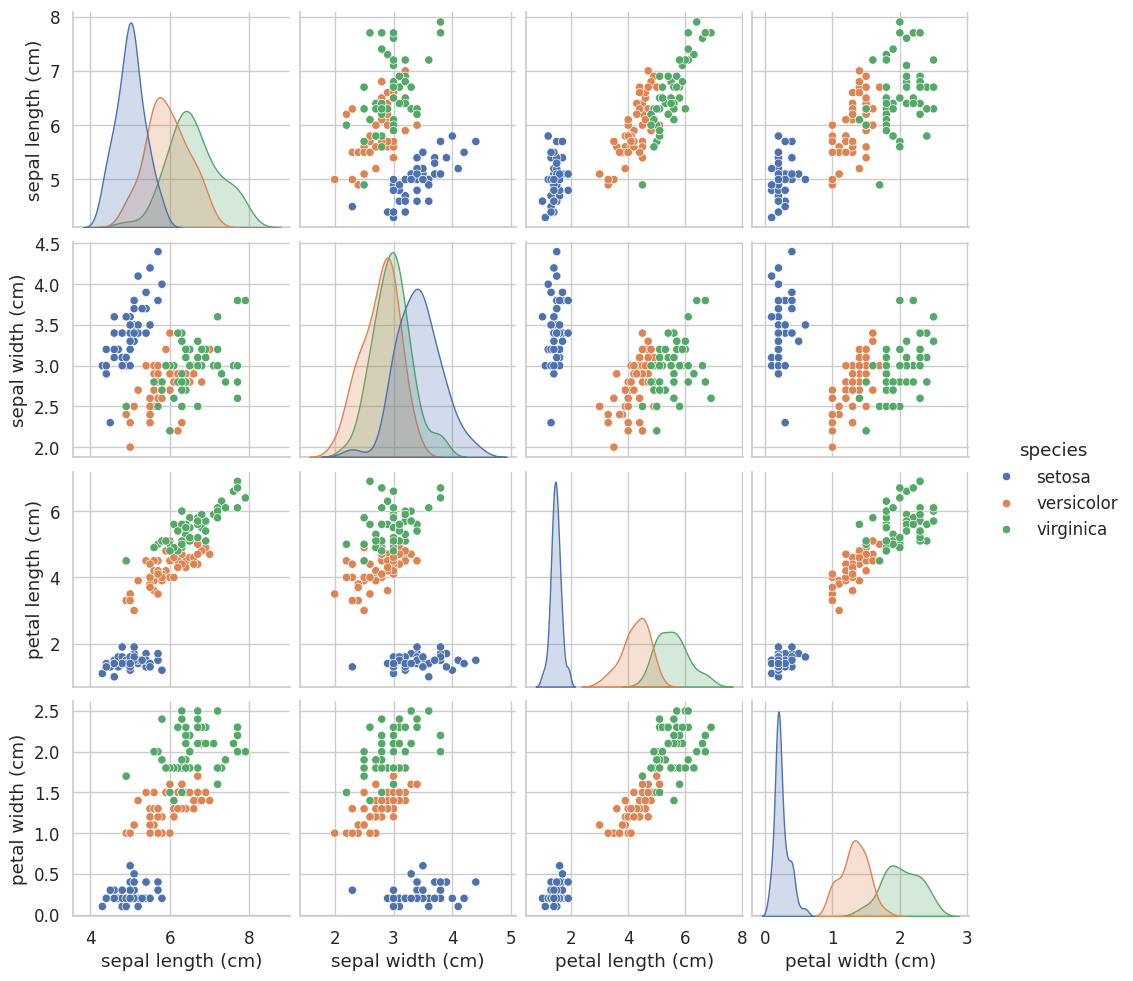

In [ ]:
# Visualizando los datos con Seaborn
import seaborn as sns

sns.set(font_scale=1.1)

sns.set_style('whitegrid')

grid = sns.pairplot(data=iris_df, vars=iris_df.columns[0:4],
     hue='species')

# Clustering

Análisis de grupos o agrupamiento es la tarea de agrupar objetos por similitud, en grupos o conjuntos de manera que los miembros del mismo grupo tengan características similares.

El análisis de grupo estuvo originado en antropología por Driver y Kroeber en 1932 e introducido a psicología por Zubin en 1938, que también fue utilizado por Cattell al principio de 1943 para clasificación de la personalidad psicológica basada en teoría de rasgos. El primer uso del término moderno data clustering (agrupamiento de datos) se remonta a 1954.

El algoritmo de agrupamiento K-means fue publicado en 1955, y generalmente se lo considera el primer algoritmo de agrupamiento.

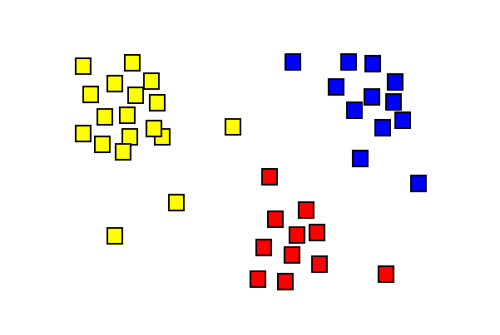

In [ ]:
# Agrupamiento (clustering) por K-medias

# Creando el estimador
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=8)

# Fitting the Model
kmeans.fit(iris.data)

# Resultados del agrupamiento
print('Agrupamiento para setosa')
print(kmeans.labels_[0:50])
print(iris.target[0:50])
print('Agrupamiento para versicolor')
print(kmeans.labels_[50:100])
print(iris.target[50:100])
print('Agrupamiento para virginica')
print(kmeans.labels_[100:150])
print(iris.target[100:150])

Agrupamiento para setosa
[1 1 1 1 1 7 1 1 1 1 7 1 1 1 7 7 7 1 7 7 7 7 1 1 1 1 1 7 1 1 1 7 7 7 1 1 7
 1 1 1 1 1 1 1 7 1 7 1 7 1]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0]
Agrupamiento para versicolor
[6 6 6 4 6 0 6 4 6 4 4 0 4 0 4 6 0 4 0 4 0 4 0 0 6 6 6 6 0 4 4 4 4 0 0 0 6
 0 4 4 4 0 4 4 4 4 4 6 4 4]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1]
Agrupamiento para virginica
[5 0 3 2 5 3 4 3 2 3 5 2 5 0 0 5 2 3 3 0 5 0 3 0 5 3 0 0 2 3 3 3 2 0 2 3 5
 2 0 5 5 5 0 5 5 5 0 2 5 0]
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [ ]:
iris_df['cluster_labels'] = kmeans.labels_
iris_df.head()

,sepal length (cm),sepal width (cm),...,species,cluster_labels
0,5.1,3.5,...,setosa,1
1,4.9,3.0,...,setosa,1
2,4.7,3.2,...,setosa,1
3,4.6,3.1,...,setosa,1
4,5.0,3.6,...,setosa,1


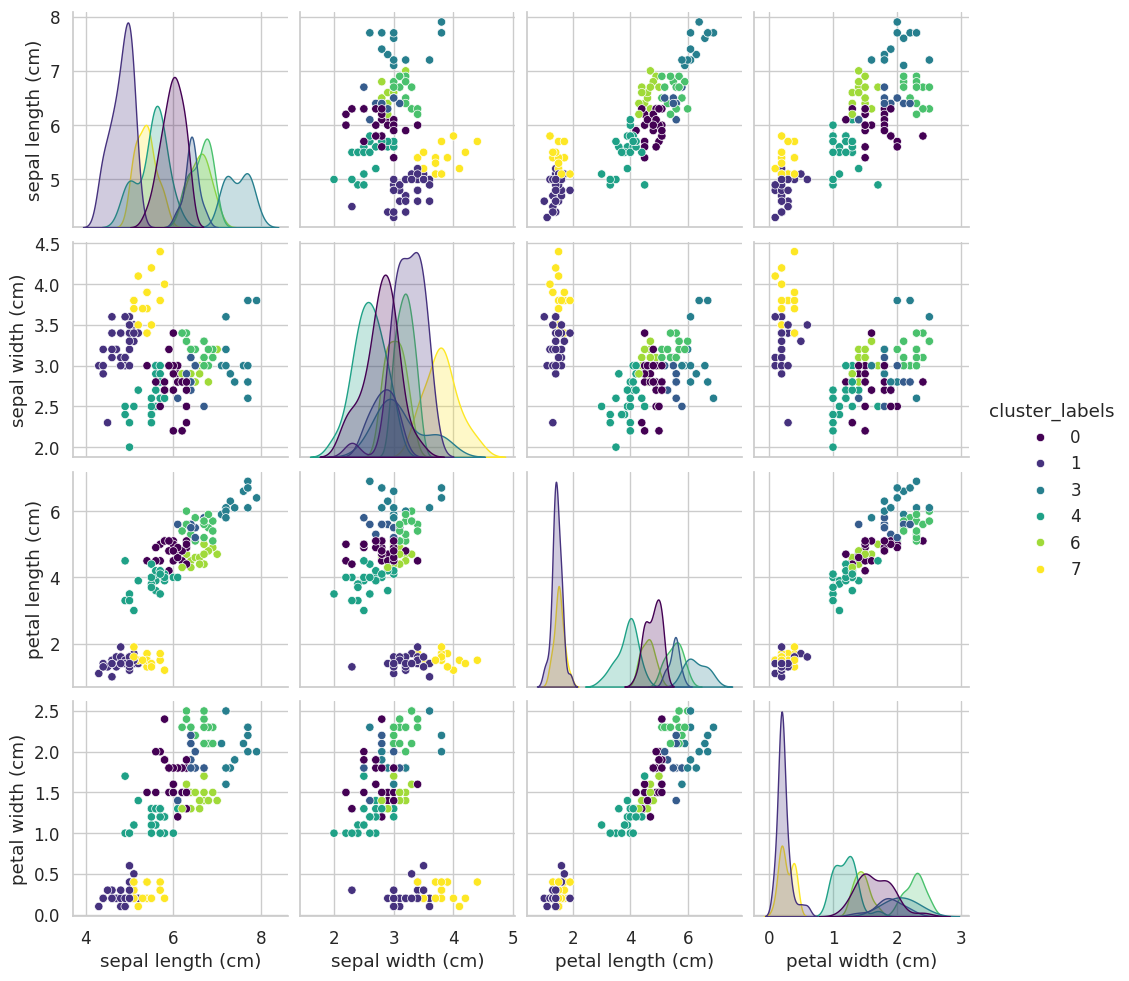

In [ ]:
sns.set(font_scale=1.1)
sns.set_style('whitegrid')

# Visualize the clusters using a pairplot
grid = sns.pairplot(data=iris_df, vars=iris_df.columns[0:4], hue='cluster_labels', palette='viridis')
